# 06 — Improvements + a second model type (validation only)
Each experiment makes **one change** and is compared on the **validation** set only (the test set is kept for the end). Finished models are not retrained, and an interrupted run continues from its last finished epoch: if the machine shuts down or Colab disconnects, re-run the cell.

Experiments:
1. `b0_512` — image size 384 → 512 (small growth plate details are clearer)
2. `b3_384` — bigger backbone (EfficientNet-B0 → B3)
3. TTA and 4. ensemble — prediction only, no training needed
5. `scratch_cnn_cls` — **a different model type**: CNN without pretraining + classification (soft label). It is not part of the ensemble; it is a separate comparison showing the combined effect of dropping pretraining and regression.

In [1]:
# On Colab: mount Drive and work from the project's notebooks folder
import os, sys
if "google.colab" in sys.modules and not os.getcwd().endswith("notebooks"):
    from google.colab import drive
    drive.mount("/content/drive")
    %cd /content/drive/MyDrive/bone-age/notebooks
%run 00_common.ipynb

In [2]:
EXPERIMENTS = {
    "b0_512": dict(backbone="efficientnet_b0", img_size=512),  # 1. larger images
    "b3_384": dict(backbone="efficientnet_b3", img_size=384),  # 2. bigger backbone
    "scratch_cnn_cls": dict(backbone="scratch_cnn", img_size=384),  # 5. no pretraining + classification
}
for name, kwargs in EXPERIMENTS.items():
    print(f"=== {name} ===")
    train_model(name, **kwargs)  # skips finished runs, resumes interrupted ones

=== b0_512 ===


train:   0%|          | 0/630 [00:00<?, ?it/s]

predict:   0%|          | 0/79 [00:00<?, ?it/s]

epoch 01 | train MAE 13.84 | val MAE 10.73 mo | 173s *


train:   0%|          | 0/630 [00:00<?, ?it/s]

predict:   0%|          | 0/79 [00:00<?, ?it/s]

... (197 outputs left out)

epoch 29 | train MAE 8.00 | val MAE 7.89 mo | 143s 


train:   0%|          | 0/630 [00:00<?, ?it/s]

predict:   0%|          | 0/79 [00:00<?, ?it/s]

epoch 30 | train MAE 8.09 | val MAE 7.81 mo | 143s *
Best val MAE: 7.81 months


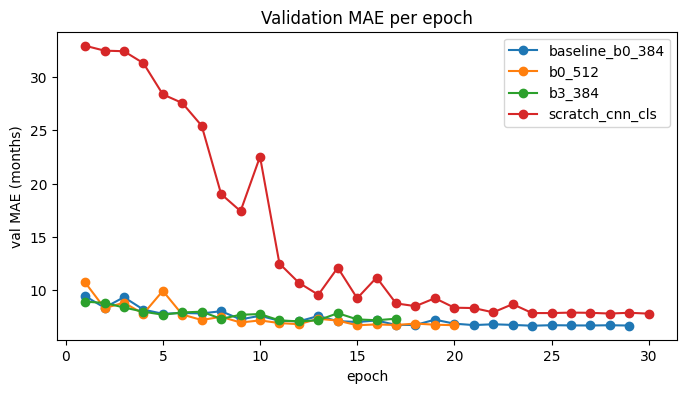

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["baseline_b0_384", *EXPERIMENTS]:
    log = pd.read_csv(OUTPUT_DIR / name / "log.csv")
    ax.plot(log["epoch"], log["val_mae_months"], "o-", label=name)
ax.set(xlabel="epoch", ylabel="val MAE (months)", title="Validation MAE per epoch")
ax.legend()
fig.savefig(OUTPUT_DIR / "experiments_val_curves.png", dpi=120, bbox_inches="tight")
plt.show()

3. TTA and 4. ensemble (the average of several models) need no training, only prediction:

In [4]:
candidates = [
    (["baseline_b0_384"], False),
    (["b0_512"], False),
    (["b3_384"], False),
    (["scratch_cnn_cls"], False),
    (["baseline_b0_384"], True),
    (["b0_512"], True),
    (["b3_384"], True),
    (["scratch_cnn_cls"], True),
    (["baseline_b0_384", "b0_512", "b3_384"], False),
    (["baseline_b0_384", "b0_512", "b3_384"], True),
]
rows = []
for runs, tta in candidates:
    _, m = evaluate(runs, "val", tta)
    rows.append({"setup": " + ".join(runs) + (" + TTA" if tta else ""), "runs": runs, "tta": tta,
                 "val_mae": m["mae"], "val_rmse": m["rmse"], "val_r2": m["r2"]})
results = pd.DataFrame(rows).sort_values("val_mae").reset_index(drop=True)
results.to_json(OUTPUT_DIR / "experiments.json", orient="records", indent=2)
results[["setup", "val_mae", "val_rmse", "val_r2"]].round(3)

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

... (19 outputs left out)

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

,setup,val_mae,val_rmse,val_r2
0,baseline_b0_384 + b0_512 + b3_384 + TTA,6.255,8.207,0.961
1,baseline_b0_384 + b0_512 + b3_384,6.300,8.269,0.960
2,baseline_b0_384 + TTA,6.549,8.528,0.958
3,b0_512 + TTA,6.616,8.602,0.957
4,baseline_b0_384,6.674,8.702,0.956
5,b0_512,6.717,8.751,0.955
6,b3_384 + TTA,6.937,9.066,0.952
7,b3_384,7.087,9.313,0.949
8,scratch_cnn_cls + TTA,7.675,9.899,0.943
9,scratch_cnn_cls,7.807,10.114,0.940
